# Etapa 2: Extracción, limpieza y transformación de datos
**Reto Global Classroom – Analítica de Airbnb · Ciudad seleccionada: Hawái (Inside Airbnb, corte del 17-sep-2026)**

Rol: Ingeniería de datos.

**Objetivo:** dejar el archivo `listings` en un formato listo para el análisis exploratorio (Etapa 3) y los modelos (Etapa 4): sin faltantes, con formatos consistentes, variables codificadas, solo variables relevantes y outliers tratados.

**Salidas de este notebook**
- `listings_limpio.csv`: datos limpios con categorías legibles, para el EDA.
- `listings_modelo.csv`: datos limpios y codificados (todo numérico), para los modelos.

**Estructura:** 1) carga · 2) exploración inicial · 3) variables nuevas · 4) selección de variables · 5) formatos · 6) faltantes · 7) outliers · 8) codificación · 9) verificación y exportación.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

RUTA = "listings.csv"          # archivo descomprimido de listings.csv.gz (detallado)
log = {}                       # bitácora de la limpieza, se usa para el reporte

## 1. Carga de datos

In [2]:
df_raw = pd.read_csv(RUTA)
df = df_raw.copy()
log["filas_iniciales"], log["columnas_iniciales"] = df_raw.shape
print("Filas, columnas:", df_raw.shape)
df.head(3)

Filas, columnas: (38779, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,784020,https://www.airbnb.com/rooms/784020,20260917204833,2026-09-21,NaN,#1 Guest Favorite for Napili & Kapalua Bays!,Enjoy this luxury residence with beautiful bam...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4134387,https://www.airbnb.com/users/show/4134387,1462533788759355031,https://www.airbnb.com/users/profile/146253378...,Jeff,NaN,13,10,13,10,"Lahaina, HI",I love hospitality and helping people create s...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/14ecd...,NaN,2,NaN,NaN,t,t,NaN,Lahaina,Maui,20.995184,-156.665009,Entire townhouse,Entire home/apt,8,NaN,2.5 baths,3.0,5.0,"[""Long term stays allowed"", ""Children\u2019s d...",$848.33,2026-09-23,2026-09-26,2545.0,848.33,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",3.0,1125.0,3.0,3.0,1125.0,1125.0,3.0,1125.0,NaN,t,15,31,42,192,2026-09-21,169,27,0,42,30,162,137429.0,2017-04-26,2026-07-21,4.96,4.97,4.92,4.97,4.93,4.97,4.80,"430020680015, TA-094-797-4144-00",NaN,1,1,0,0,1.48
1,461638,https://www.airbnb.com/rooms/461638,20260917204833,2026-09-19,NaN,The Lotus Garden-Sugar Room/Downtown Hilo,If you want a convenient base for seeing the i...,NaN,https://a0.muscache.com/pictures/99ab04c0-eb8b...,2128914,https://www.airbnb.com/users/show/2128914,1462522384134588935,https://www.airbnb.com/users/profile/146252238...,Megan,NaN,14,5,14,5,"Hilo, HI",Aloha I'm Megan. Meet Jasper also. We've been ...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/2128914/profi...,NaN,5,NaN,NaN,t,t,NaN,South Hilo,Hawaii,19.721000,-155.084950,Private room in cottage,Private room,1,NaN,1 shared bath,1.0,1.0,"[""Long term stays allowed"", ""Kitchen"", ""Free s...",$101.86,2026-09-19,2026-09-26,713.0,101.86,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",7.0,180.0,7.0,7.0,180.0,180.0,7.0,180.0,NaN,t,30,60,90,90,2026-09-19,438,3,0,90,0,42,4278.0,2012-05-18,2026-08-12,4.68,4.74,4.81,4.83,4.82,4.81,4.59,W85296321-01,NaN,5,3,2,0,2.51
2,479121,https://www.airbnb.com/rooms/479121,20260917204833,2026-09-19,NaN,Tropical Relaxing Loft: Spacious and Unique,Tucked in a quiet ocean side area on the east ...,NaN,https://a0.muscache.com/pictures/05bd7136-dc5e...,4599607,https://www.airbnb.com/users/show/4599607,1462661189318434518,https://www.airbnb.com/users/profile/146266118...,SherylRose,NaN,13,8,13,4,"California, United States

## 2. Exploración inicial

In [3]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(1),
    "valores_unicos": df.nunique(),
})
print("Tipos de variable:")
print(resumen["tipo"].value_counts().to_string())
print("\nIDs duplicados:", df["id"].duplicated().sum(), "| filas totalmente duplicadas:", df.duplicated().sum())
resumen.sort_values("pct_nulos", ascending=False).head(35)

Tipos de variable:
tipo
float64    36
str        30
int64      24

IDs duplicados: 0 | filas totalmente duplicadas: 0


,tipo,nulos,pct_nulos,valores_unicos
neighborhood_overview,float64,38779,100.0,0
host_since,float64,38779,100.0,0
host_response_time,float64,38779,100.0,0
host_thumbnail_url,float64,38779,100.0,0
host_acceptance_rate,float64,38779,100.0,0
host_response_rate,float64,38779,100.0,0
host_verifications,float64,38779,100.0,0
neighbourhood,float64,38779,100.0,0
host_total_listings_count,float64,38779,100.0,0
host_neighbourhood,float64,38779,100.0,0


In [4]:
vacias = resumen.index[resumen["pct_nulos"] == 100].tolist()
log["columnas_100pct_vacias"] = len(vacias)
print(f"{len(vacias)} columnas 100% vacías:\n", vacias)

13 columnas 100% vacías:
 ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'bathrooms', 'calendar_updated', 'instant_bookable']


**Hallazgos de la exploración**
- Hay columnas que vienen **completamente vacías** en esta versión del archivo (incluidas `bathrooms`, `host_since`, `host_response_rate`, `host_acceptance_rate`, `instant_bookable`); no aportan información y se eliminan.
- `price` viene como texto con símbolo `$` y debe convertirse a número. Es la variable objetivo.
- ~9 % de los anuncios no tiene precio.
- Las reseñas faltan (~25 %) porque el anuncio no tiene reseñas; no es un error de captura.
- Existen columnas `price_quote_*` y `estimated_revenue_l365d` que **contienen el precio** (o se derivan de él): usarlas como predictoras causaría *fuga de datos*.

In [5]:
# Verificación de la fuga de datos: el precio por noche de la cotización es idéntico a `price`
p = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)
print("Diferencia máxima entre price y price_quote_price_per_night:",
      (p.round(2) - df["price_quote_price_per_night"]).abs().max())

Diferencia máxima entre price y price_quote_price_per_night: 0.0


## 3. Variables nuevas (ingeniería de características)
Se crean **antes** de eliminar las columnas originales de las que se derivan.

In [6]:
# --- Baños: de texto ("1.5 baths", "1 shared bath", "Half-bath") a número + indicador de compartido
txt = df["bathrooms_text"].str.lower()
df["banos"] = txt.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
df.loc[txt.str.contains("half", na=False) & df["banos"].isna(), "banos"] = 0.5
df["bano_compartido"] = txt.str.contains("shared", na=False).astype(int)

# --- Amenidades: conteo total + indicadores de las más relevantes para el precio en Hawái
lista_am = df["amenities"].apply(lambda s: [a.lower() for a in json.loads(s)] if isinstance(s, str) else [])
df["n_amenidades"] = lista_am.str.len()

def tiene(lista, claves, excluir=()):
    return int(any(any(k in a for k in claves) and not any(e in a for e in excluir) for a in lista))

amenidades = {
    "am_piscina":        (["pool"], ["pool table"]),
    "am_jacuzzi":        (["hot tub"], []),
    "am_aire_acond":     (["air conditioning"], []),
    "am_wifi":           (["wifi"], []),
    "am_cocina":         (["kitchen"], []),
    "am_lavadora":       (["washer"], ["dishwasher"]),
    "am_estacionamiento":(["parking"], []),
    "am_acceso_playa":   (["beach access"], []),
    "am_vista_mar":      (["ocean view", "sea view", "beach view"], []),
    "am_gimnasio":       (["gym"], []),
    "am_bbq":            (["bbq grill"], []),
    "am_tv":             (["tv"], []),
}
for nombre, (claves, excluir) in amenidades.items():
    df[nombre] = lista_am.apply(lambda l: tiene(l, claves, excluir))
df[[c for c in df.columns if c.startswith("am_")]].mean().round(3).sort_values(ascending=False)

am_wifi               0.990
am_tv                 0.959
am_cocina             0.910
am_estacionamiento    0.900
am_lavadora           0.815
am_piscina            0.785
am_aire_acond         0.710
am_bbq                0.630
am_acceso_playa       0.518
am_jacuzzi            0.482
am_gimnasio           0.326
am_vista_mar          0.231
dtype: float64

In [7]:
# --- Licencia: de texto libre a 3 categorías
lic = df["license"].fillna("").str.strip().str.lower()
df["licencia"] = np.where(lic == "", "sin_licencia", np.where(lic.str.contains("exempt"), "exenta", "con_licencia"))

# --- Anfitrión: ¿vive en Hawái?  (host_location vacío se considera "no confirmado")
loc = df["host_location"].fillna("").str.lower()
df["host_en_hawaii"] = loc.str.contains(r"\bhi\b|hawaii").astype(int)

# --- Antigüedad como anfitrión (años con decimales)
df["anios_anfitrion"] = df["hosts_time_as_host_years"] + df["hosts_time_as_host_months"] / 12

# --- Reseñas: fechas -> tiempos relativos a la fecha de raspado
ref = pd.to_datetime(df["calendar_last_scraped"]).max()
df["antiguedad_resenas_anios"] = (ref - pd.to_datetime(df["first_review"])).dt.days / 365.25
df["dias_desde_ultima_resena"] = (ref - pd.to_datetime(df["last_review"])).dt.days
df["tiene_resenas"] = (df["number_of_reviews"] > 0).astype(int)
print("Fecha de referencia:", ref.date())

Fecha de referencia: 2026-09-21


## 4. Selección de variables relevantes
Se descartan las que no aportan al análisis posterior, por grupo:

In [8]:
identificadores = ["id", "listing_url", "scrape_id", "picture_url", "host_id", "host_url", "host_profile_id",
                   "host_profile_url", "host_name", "host_thumbnail_url", "host_picture_url"]
texto_libre     = ["name", "description", "host_about", "neighborhood_overview"]
fuga_de_datos   = [c for c in df.columns if c.startswith("price_quote")] + ["estimated_revenue_l365d"]
ya_transformadas = ["bathrooms_text", "amenities", "license", "host_location", "first_review", "last_review",
                    "hosts_time_as_host_years", "hosts_time_as_host_months"]
redundantes     = ["minimum_minimum_nights", "maximum_minimum_nights", "minimum_maximum_nights",
                   "maximum_maximum_nights", "minimum_nights_avg_ntm", "maximum_nights_avg_ntm",
                   "availability_60", "availability_90", "availability_eoy",
                   "hosts_time_as_user_years", "hosts_time_as_user_months",
                   "host_listings_count", "calculated_host_listings_count_entire_homes",
                   "calculated_host_listings_count_private_rooms", "calculated_host_listings_count_shared_rooms",
                   "number_of_reviews_l30d", "number_of_reviews_ly", "has_availability"]
sin_variacion_o_tecnicas = ["host_has_profile_pic", "last_scraped", "calendar_last_scraped", "source"]

a_eliminar = set(vacias + identificadores + texto_libre + fuga_de_datos + ya_transformadas
                 + redundantes + sin_variacion_o_tecnicas)
a_eliminar = [c for c in df.columns if c in a_eliminar]
df = df.drop(columns=a_eliminar)
log["columnas_eliminadas"] = len(a_eliminar)
print(f"Columnas eliminadas: {len(a_eliminar)} | columnas restantes: {df.shape[1]}")

Columnas eliminadas: 62 | columnas restantes: 49


## 5. Formatos consistentes

In [9]:
# --- Precio: texto "$1,250.00" -> float. Filas sin precio se eliminan (es la variable objetivo).
df["price"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)
log["filas_sin_precio"] = int(df["price"].isna().sum())
df = df.dropna(subset=["price"]).reset_index(drop=True)

# --- Booleanos t/f -> 1/0
for c in ["host_is_superhost", "host_identity_verified"]:
    df[c] = df[c].map({"t": 1, "f": 0}).astype(int)

# --- Texto de categóricas: sin espacios sobrantes y tipo uniforme
cat_cols = ["room_type", "property_type", "neighbourhood_cleansed", "neighbourhood_group_cleansed", "licencia"]
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip()

print("Filas sin precio eliminadas:", log["filas_sin_precio"], "| filas restantes:", len(df))
df.dtypes.astype(str).value_counts()

Filas sin precio eliminadas: 3654 | filas restantes: 35125


int64      25
float64    19
str         5
Name: count, dtype: int64

## 6. Datos faltantes

In [10]:
faltantes = df.isna().sum()
faltantes[faltantes > 0].to_frame("nulos").assign(pct=lambda x: (x["nulos"] / len(df) * 100).round(1))

,nulos,pct
bedrooms,57,0.2
beds,613,1.7
minimum_nights,187,0.5
maximum_nights,187,0.5
review_scores_rating,8207,23.4
review_scores_accuracy,8210,23.4
review_scores_cleanliness,8210,23.4
review_scores_checkin,8210,23.4
review_scores_communication,8210,23.4
review_scores_location,8210,23.4


**Estrategia por grupo**

| Variable(s) | Causa | Tratamiento |
|---|---|---|
| `bedrooms`, `beds`, `banos` | pocos faltantes (<3 %) | mediana por tipo de habitación |
| `minimum_nights`, `maximum_nights` | <1 % | mediana global |
| puntajes de reseñas (`review_scores_*`) | el anuncio no tiene reseñas | mediana + indicador `tiene_resenas` (ya creado) |
| `reviews_per_month` | sin reseñas | 0 |
| `antiguedad_resenas_anios` | sin reseñas | 0 |
| `dias_desde_ultima_resena` | sin reseñas | máximo observado (equivale a "hace mucho") |

In [11]:
for c in ["bedrooms", "beds", "banos"]:
    df[c] = df[c].fillna(df.groupby("room_type")[c].transform("median"))
    df[c] = df[c].fillna(df[c].median())

for c in ["minimum_nights", "maximum_nights"]:
    df[c] = df[c].fillna(df[c].median())

puntajes = [c for c in df.columns if c.startswith("review_scores_")]
for c in puntajes:
    df[c] = df[c].fillna(df[c].median())

df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df["antiguedad_resenas_anios"] = df["antiguedad_resenas_anios"].fillna(0)
df["dias_desde_ultima_resena"] = df["dias_desde_ultima_resena"].fillna(df["dias_desde_ultima_resena"].max())

print("Nulos restantes:", int(df.isna().sum().sum()))

Nulos restantes: 0


## 7. Análisis y tratamiento de outliers
Primero se revisan valores imposibles o poco razonables en las noches mínimas/máximas; luego los de la variable objetivo (`price`), que tiene una cola derecha muy larga.

minimum_nights  > 365: 0 | maximum_nights > 1125: 22


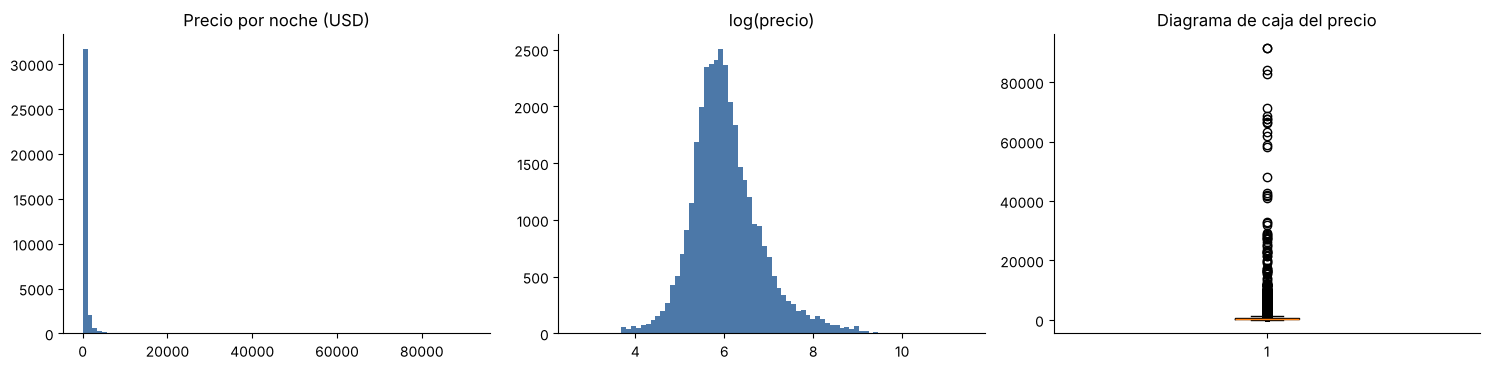

,price
count,35125.0
mean,682.1
std,1907.4
min,15.0
1%,74.0
5%,139.5
50%,384.0
95%,1868.0
99%,5254.1
max,91455.0


In [12]:
# --- Noches mínimas / máximas: hay valores absurdos (p. ej. 2.147.483.647 noches). Se topan en límites razonables.
print("minimum_nights  > 365:", (df["minimum_nights"] > 365).sum(), "| maximum_nights > 1125:", (df["maximum_nights"] > 1125).sum())
df["minimum_nights"] = df["minimum_nights"].clip(upper=365)
df["maximum_nights"] = df["maximum_nights"].clip(upper=1125)

# --- Precio: distribución original y en escala logarítmica
df["log_price"] = np.log(df["price"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df["price"], bins=80, color="#4c78a8"); ax[0].set_title("Precio por noche (USD)")
ax[1].hist(df["log_price"], bins=80, color="#4c78a8"); ax[1].set_title("log(precio)")
ax[2].boxplot(df["price"]); ax[2].set_title("Diagrama de caja del precio")
plt.tight_layout(); plt.show()
df["price"].describe(percentiles=[.01, .05, .5, .95, .99]).round(1).to_frame("price")

El precio es muy asimétrico (unos pocos anuncios de miles de USD/noche). En escala logarítmica la distribución es casi simétrica, así que el criterio de rango intercuartílico (IQR) se aplica sobre `log(price)`: es más justo que aplicarlo al precio crudo, donde marcaría como "outlier" casi todo lo que sea de lujo.

In [13]:
q1, q3 = df["log_price"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Límites en USD: {np.exp(lim_inf):,.0f} a {np.exp(lim_sup):,.0f} por noche")

mask_out = (df["log_price"] < lim_inf) | (df["log_price"] > lim_sup)
print("Outliers bajos:", int((df['log_price'] < lim_inf).sum()), "| altos:", int((df['log_price'] > lim_sup).sum()),
      f"| total: {mask_out.sum()} ({mask_out.mean()*100:.1f} %)")
print("\nTipos de habitación entre los outliers altos:")
print(df.loc[df["log_price"] > lim_sup, "room_type"].value_counts().to_string())

Límites en USD: 68 a 2,411 por noche
Outliers bajos: 293 | altos: 1242 | total: 1535 (4.4 %)

Tipos de habitación entre los outliers altos:
room_type
Entire home/apt    1210
Private room         30
Hotel room            2


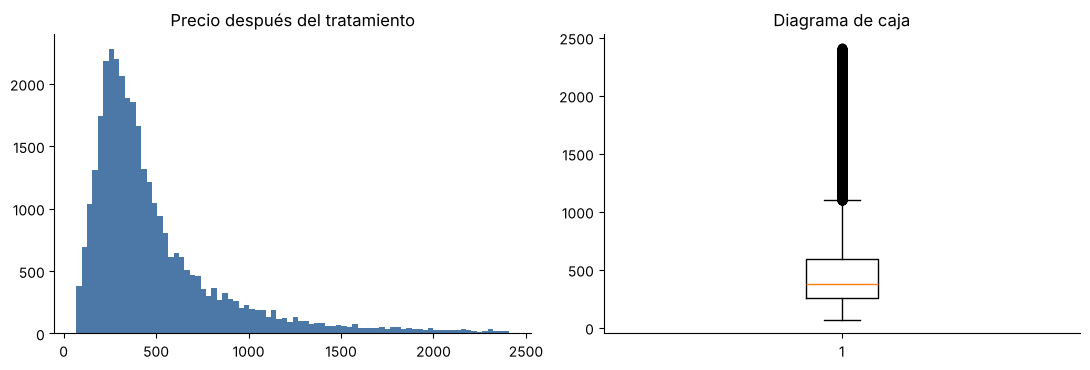

Filas restantes: 33590


In [14]:
log["outliers_precio_eliminados"] = int(mask_out.sum())
log["limite_inferior_usd"], log["limite_superior_usd"] = round(float(np.exp(lim_inf))), round(float(np.exp(lim_sup)))
df = df.loc[~mask_out].reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df["price"], bins=80, color="#4c78a8"); ax[0].set_title("Precio después del tratamiento")
ax[1].boxplot(df["price"]); ax[1].set_title("Diagrama de caja")
plt.tight_layout(); plt.show()
print("Filas restantes:", len(df))

**Decisión:** se eliminan los anuncios fuera de los límites IQR sobre `log(price)` (precios casi simbólicos o de cifras extremas, que probablemente son errores de captura o propiedades atípicas que distorsionarían el modelo). Se conserva `log_price` como variable auxiliar: **si se usa como objetivo, no puede ser predictora a la vez que `price`.**

## 8. Codificación de variables categóricas
Las categorías con muchas clases se agrupan primero (las menores a 1 % pasan a `Other`) para no generar decenas de columnas casi vacías.

In [15]:
def agrupar_raras(s, min_frac=0.01, etiqueta="Other"):
    frec = s.value_counts(normalize=True)
    raras = frec[frec < min_frac].index
    return s.where(~s.isin(raras), etiqueta)

print("Categorías antes -> después de agrupar")
for c in ["property_type", "neighbourhood_cleansed"]:
    antes = df[c].nunique()
    df[c] = agrupar_raras(df[c])
    print(f"  {c}: {antes} -> {df[c].nunique()}")

# Versión legible (para el EDA de la Etapa 3)
df_limpio = df.copy()

# Versión codificada (para los modelos): one-hot, sin la primera categoría para evitar colinealidad
df_modelo = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print("\nDimensiones -> limpio:", df_limpio.shape, "| modelo:", df_modelo.shape)

Categorías antes -> después de agrupar


  property_type: 80 -> 12
  neighbourhood_cleansed: 30 -> 15

Dimensiones -> limpio: (33590, 50) | modelo: (33590, 78)


## 9. Verificación final y exportación

In [16]:
# Requisitos de la etapa
assert df_limpio.isna().sum().sum() == 0, "Hay faltantes en df_limpio"
assert df_modelo.isna().sum().sum() == 0, "Hay faltantes en df_modelo"
assert not (df_limpio.astype(str).isin(["N", "NaN", "nan", "None", ""]).any().any()), "Hay marcadores de faltante en texto"
assert all(pd.api.types.is_numeric_dtype(t) for t in df_modelo.dtypes), "Hay columnas no numéricas en df_modelo"

log["filas_finales"], log["columnas_finales_limpio"] = df_limpio.shape
log["columnas_finales_modelo"] = df_modelo.shape[1]
print("OK: sin faltantes, formatos consistentes y variables numéricas codificadas.\n")
pd.Series(log, name="valor").to_frame()

OK: sin faltantes, formatos consistentes y variables numéricas codificadas.



,valor
filas_iniciales,38779
columnas_iniciales,90
columnas_100pct_vacias,13
columnas_eliminadas,62
filas_sin_precio,3654
outliers_precio_eliminados,1535
limite_inferior_usd,68
limite_superior_usd,2411
filas_finales,33590
columnas_finales_limpio,50


In [17]:
df_limpio.to_csv("listings_limpio.csv", index=False)
df_modelo.to_csv("listings_modelo.csv", index=False)
print("Guardados: listings_limpio.csv, listings_modelo.csv")
df_limpio.describe().T.round(2).head(40)

Guardados: listings_limpio.csv, listings_modelo.csv


,count,mean,std,min,25%,50%,75%,max
host_is_superhost,33590.0,0.55,0.50,0.00,0.00,1.00,1.00,1.00
host_identity_verified,33590.0,0.97,0.18,0.00,1.00,1.00,1.00,1.00
latitude,33590.0,20.91,0.81,18.99,20.69,20.96,21.29,22.23
longitude,33590.0,-157.21,1.28,-159.72,-157.84,-156.69,-156.44,-154.84
accommodates,33590.0,4.79,2.32,1.00,4.00,4.00,6.00,16.00
bedrooms,33590.0,1.55,1.07,0.00,1.00,1.00,2.00,15.00
beds,33590.0,2.62,1.49,1.00,2.00,2.00,3.00,26.00
price,33590.0,495.15,377.42,67.72,257.12,375.50,594.00,2409.80
minimum_nights,33590.0,5.81,19.22,1.00,1.00,2.00,3.00,365.00
maximum_nights,33590.0,527.10,428.75,1.00,179.00,365.00,1125.00,1125.00


## Descripción del conjunto de datos final (para el reporte de 1 página)
- **Fuente:** Inside Airbnb, `listings.csv.gz` de Hawái (corte 17-sep-2026).
- **Unidad de análisis:** un anuncio. **Variable objetivo:** `price` (USD por noche), con `log_price` como apoyo.
- **Grupos de variables finales:** características físicas (`accommodates`, `bedrooms`, `beds`, `banos`), ubicación (`latitude`, `longitude`, barrio, isla), tipo de propiedad y habitación, amenidades (`n_amenidades` y 12 indicadores `am_*`), reglas de estadía (`minimum_nights`, `maximum_nights`), disponibilidad y demanda, reseñas y puntajes, y perfil del anfitrión (superhost, verificación, antigüedad, número de anuncios, residencia).
- Las cifras de la bitácora `log` (arriba) son las que van en el reporte: filas y columnas iniciales/finales, columnas vacías, filas sin precio y outliers eliminados.